In [1]:
import pandas as pd
import numpy as np
import wfdb
import ast

def load_raw_data(df, sampling_rate, path):
    if sampling_rate == 100:
        data = [wfdb.rdsamp(path+f) for f in df.filename_lr]
    else:
        data = [wfdb.rdsamp(path+f) for f in df.filename_hr]
    data = np.array([signal for signal, meta in data])
    return data

path = '/Users/shaun/Downloads/PTB_DATASET/'
sampling_rate=100

# load and convert annotation data
Y = pd.read_csv('/Users/shaun/Downloads/PTB_DATASET/ptbxl_database.csv', index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))

# Load raw signal data
X = load_raw_data(Y, sampling_rate, path)

# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv('/Users/shaun/Downloads/PTB_DATASET/scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))

# Apply diagnostic superclass
Y['diagnostic_superclass'] = Y.scp_codes.apply(aggregate_diagnostic)

# Split data into train and test
test_fold = 10
# Train
X_train = X[np.where(Y.strat_fold != test_fold)]
y_train = Y[(Y.strat_fold != test_fold)].diagnostic_superclass
# Test
X_test = X[np.where(Y.strat_fold == test_fold)]
y_test = Y[Y.strat_fold == test_fold].diagnostic_superclass

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(19601, 1000, 12) (19601,) (2198, 1000, 12) (2198,)


In [20]:
Xf_train = X_train[:, :, 0]  # stands for x_fixed
Xf_test = X_test[:, :, 0]

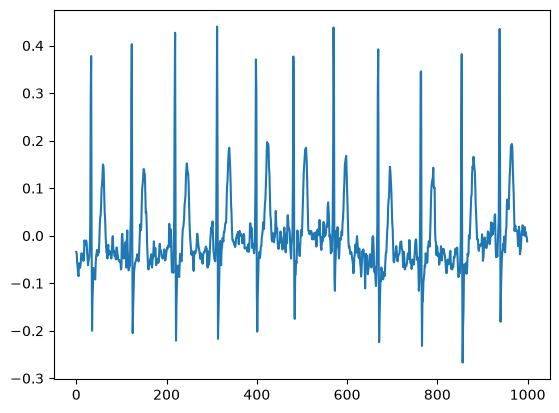

In [24]:
import matplotlib.pyplot as plt 

plt.plot(Xf_train[4])

In [15]:
from sklearn.preprocessing import MultiLabelBinarizer

list_of_conditions = ['CD', 'STTC', 'MI', 'NORM', 'HYP']

mlb = MultiLabelBinarizer(classes=list_of_conditions)

y_train_bin = mlb.fit_transform(y_train)
y_test_bin = mlb.transform(y_test)

print(y_train_bin.shape)
# Output: (N, 5)


(19601, 5)


In [26]:
Xf_train = X_train[:, :, 0] # stands for X fixed very logical (takes the first lead)
Xf_test = X_test[:, :, 0]

In [30]:
Xf_train

array([[-0.119, -0.116, -0.12 , ...,  0.069,  0.086,  0.022],
       [ 0.004, -0.02 , -0.053, ...,  0.121, -0.326, -0.348],
       [-0.029, -0.035, -0.054, ..., -0.029, -0.048, -0.049],
       ...,
       [ 0.038,  0.078, -0.014, ..., -0.106, -0.045,  0.463],
       [-0.057, -0.041,  0.003, ...,  0.033,  0.027, -0.006],
       [-0.049, -0.049, -0.059, ...,  0.091,  0.175,  0.166]],
      shape=(19601, 1000))

In [27]:
y_train_bin

array([[0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0],
       ...,
       [0, 1, 0, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0]], shape=(19601, 5))

In [29]:
np.unique(y_test)
list_of_conditions = ['CD', 'STTC', 'MI', 'NORM', "HYP"]

In [6]:
import numpy as np
import pandas as pd

values, counts = np.unique(y_test, return_counts=True)

df_freq = pd.DataFrame({
    'Category': values,
    'Count': counts
}).sort_values(by='Count', ascending=False).reset_index(drop=True)

df_freq['Percentage (%)'] = (df_freq['Count'] / len(y_test) * 100).round(2)

print(df_freq.to_string(index=False))


           Category  Count  Percentage (%)
             [NORM]    912           41.49
               [MI]    256           11.65
             [STTC]    242           11.01
               [CD]    184            8.37
           [MI, CD]    133            6.05
        [HYP, STTC]     73            3.32
         [MI, STTC]     61            2.78
              [HYP]     56            2.55
         [NORM, CD]     45            2.05
    [HYP, MI, STTC]     41            1.87
                 []     40            1.82
          [HYP, CD]     27            1.23
         [STTC, CD]     21            0.96
          [HYP, MI]     17            0.77
         [CD, STTC]     17            0.77
    [HYP, STTC, CD]     14            0.64
     [STTC, MI, CD]     13            0.59
    [HYP, CD, STTC]     11            0.50
[HYP, CD, MI, STTC]     11            0.50
     [CD, MI, STTC]      8            0.36
      [HYP, MI, CD]      5            0.23
[HYP, STTC, MI, CD]      5            0.23
       [NOR

In [13]:
empty_idx = np.where([len(x) == 0 for x in y_test])[0]
empty_idx

array([  50,   60,  211,  334,  335,  482,  488,  518,  615,  644,  677,
        846,  859,  885,  904,  947,  959,  972, 1018, 1077, 1248, 1256,
       1259, 1312, 1313, 1376, 1382, 1441, 1598, 1641, 1680, 1681, 1683,
       1712, 1769, 1791, 1837, 2097, 2126, 2167])

In [34]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Keep Xf_train and Xf_test in their original (N, 1000) shape
train_loader = DataLoader(
    TensorDataset(torch.tensor(Xf_train, dtype=torch.float32), torch.tensor(y_train_bin, dtype=torch.float32)),
    batch_size=64,
    shuffle=True
)
test_loader = DataLoader(
    TensorDataset(torch.tensor(Xf_test, dtype=torch.float32), torch.tensor(y_test_bin, dtype=torch.float32)),
    batch_size=64,
    shuffle=False
)

# 2. 1D CNN that accepts (Batch, 1000) directly
class ECG1DCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # PyTorch Conv1d requires a channel axis internally: (Batch, 1000) -> (Batch, 1, 1000)
        x = x.unsqueeze(1)
        return self.classifier(self.features(x))

# 3. Train & Evaluate
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ECG1DCNN(num_classes=5).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(2):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(X_batch)

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            test_loss += criterion(model(X_batch), y_batch).item() * len(X_batch)

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss/len(train_loader.dataset):.4f} | Test Loss: {test_loss/len(test_loader.dataset):.4f}")


Epoch 01 | Train Loss: 0.4626 | Test Loss: 0.4380
Epoch 02 | Train Loss: 0.4179 | Test Loss: 0.4153


In [35]:
list_of_conditions = ['CD', 'STTC', 'MI', 'NORM', 'HYP']

model.eval()
test_loss = 0.0
correct_per_class = torch.zeros(5, device=device)
total_samples = 0

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        test_loss += criterion(logits, y_batch).item() * len(X_batch)

        # Convert raw logits -> probabilities -> 0 or 1 predictions
        preds = (torch.sigmoid(logits) >= 0.5).float()

        # Sum matches per column (shape:)
        correct_per_class += (preds == y_batch).sum(dim=0)
        total_samples += len(X_batch)

avg_test_loss = test_loss / total_samples
per_class_acc = (correct_per_class / total_samples) * 100
overall_acc = per_class_acc.mean().item()

# Format per-condition accuracies cleanly on one line
breakdown = " | ".join(
    f"{cond}: {acc:.1f}%" for cond, acc in zip(list_of_conditions, per_class_acc)
)

print(
    f"Epoch {epoch+1:02d} | "
    f"Train Loss: {train_loss/len(train_loader.dataset):.4f} | "
    f"Test Loss: {avg_test_loss:.4f} | "
    f"Overall Acc: {overall_acc:.2f}%\n"
    f"   -> {breakdown}"
)


Epoch 02 | Train Loss: 0.4179 | Test Loss: 0.4153 | Overall Acc: 82.17%
   -> CD: 83.1% | STTC: 82.6% | MI: 77.6% | NORM: 78.8% | HYP: 88.9%
